# 实验六：使用卷积神经网络识别 CIFAR-10 彩色图像

第五次实验中，我们把手写数字展平后交给全连接网络。这次实验，我们将研究更加丰富多样的图像，探究 CNN 在图片颜色、位置上的处理。

这次实验仍使用 PyTorch 完成。代码中的工具函数已给出，只需完成代码中的相应部分即可。同学们在完成实验的过程中，尤其要注意以下这些内容：

1. **RGB通道**：与上次处理的灰度图不同，我们这次处理的是以张量形式存储的图片。对于这种包含更多信息的数据形式，我们又怎么进行处理？
2. **卷积核的作用**：CNN 网络最核心的一个内容就是卷积核，同学们在处理的过程中，要感受卷积核对图像局部信息提取的作用。同时也应注意到，卷积核对信息的提取与图像信息的位置无关。
3. **模型比较**：实验的最后会进行与上次实验的比较。虽然处理的是不同数据集，但在这种更复杂的数据集上， CNN 也能展示其强大之处。感受 CNN 与上次全连接网络的不同与更先进的地方。

实验主线：认识彩图 → 理解卷积 → 搭建 CNN → 检查与训练 → 比较模型 → 数据增强对照 → 最终测试与错误分析。


**参考说明：概念边界**

- 第五次的灰度图也以张量存储，本次输入通道由 1 个变为 3 个。
- 卷积在不同位置共享权重，表示相同的局部计算规则；这不保证整个分类网络对位置变化严格不变。
- 正式模型比较是在同一 CIFAR-10 数据上进行的 MLP/CNN 对照，不能用两次实验的不同数据集准确率判断模型优劣；CNN 的结构假设是否合适需要实验检验。


## 0 · 环境、文件与实验约定

依然使用之前使用的 `ai-lab` 虚拟环境即可。

由于这里的数据集较大，助教会提供两份压缩材料，一份提供数据一份不提供。如果下载不包含数据集的材料，第一次运行时将 `DOWNLOAD=True`；缓存完整后改回 `False`。

| 项目               | 本实验约定                                                                                  |
| ------------------ | ------------------------------------------------------------------------------------------- |
| 数据划分           | 官方训练部分 50,000 张固定拆成 45,000 张训练池、5,000 张验证；官方 10,000 张测试图像留到 Q7 |
| quick 模式（默认） | 从训练池固定抽取 12,000 张，验证仍为全部 5,000 张；训练 8 轮                                |
| full 模式          | 使用全部 45,000 张训练图像，验证仍为 5,000 张；训练 12 轮                                   |
| 预处理             | 像素先转 float32 的 [0,1]，再逐通道用 `(x−0.5)/0.5` 映射到 [−1,1]                           |
| 优化               | Adam，lr=0.001，batch size=128；三组主实验保持一致                                          |
| 输出与损失         | 输出十个 logits；使用 CrossEntropyLoss，不提前加 softmax                                    |
| 选模               | 验证准确率高者优先，持平时验证损失小者优先，再持平取较早轮次                                |
| 设备               | CPU即可，如果有 GPU 或 MPS 请自行查阅资料并移动数据集至相应设备上计算                       |

说明：

- quick 与 full 是两套不同的实验预算，用于区分“充分训练”和“不充分”训练的两种情况；
- Adam 是根据梯度更新参数的另一种优化器，直接使用即可。


**参考说明：训练预算**

quick 与 full 同时改变了训练样本量和训练轮数，因此只能视为两套预算。full 并不保证充分训练，quick 也不能仅凭名称认定训练不充分；需要结合曲线判断。若研究增加训练轮数的作用，应保持训练样本、模型和其他设置相同，只改变轮数。


In [1]:
import os
import platform
import sys
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import Markdown, display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import TensorDataset

assert Path("lab_utils.py").exists(), "请在实验六目录运行 notebook"
from lab_utils import (
    CLASS_NAMES_ZH,
    CLASSES,
    data_root,
    display_image,
    evaluate,
    fit_model,
    load_test,
    load_train_val,
    make_loader,
    plot_channels,
    plot_confusion,
    plot_history,
    plot_samples,
    print_comparison,
    seed_everything,
    snapshot,
    with_augmentation,
)

SEED, SPLIT_SEED, ORDER_SEED = 42, 42, 2026
MODE = os.environ.get("LAB6_MODE", "quick")  # 改为 "full" 使用完整训练池。
SETTINGS = {
    "quick": {"train_limit": 12000, "epochs": 8},
    "full": {"train_limit": None, "epochs": 12},
}
assert MODE in SETTINGS, "MODE 应为 quick 或 full"
TRAIN_LIMIT, EPOCHS = SETTINGS[MODE]["train_limit"], SETTINGS[MODE]["epochs"]
BATCH_SIZE, LR = 128, 0.001
DOWNLOAD = False
DEVICE = torch.device(os.environ.get("LAB6_DEVICE", "mps"))
torch.set_num_threads(min(4, os.cpu_count() or 1))
seed_everything(SEED)

print(
    "Python:",
    sys.version.split()[0],
    "PyTorch:",
    torch.__version__,
    "torchvision:",
    torchvision.__version__,
)
print(
    "device:",
    DEVICE,
    "machine:",
    platform.machine(),
)
print("mode:", MODE, "epochs:", EPOCHS, "batch size:", BATCH_SIZE, "lr:", LR)
print("data root:", data_root().resolve())

# CLASSES 和 CLASS_NAMES_ZH 是本次实验区分的目标，已经在工具模块中定义好
print(dict(zip(CLASSES, CLASS_NAMES_ZH)))


Python: 3.12.14 PyTorch: 2.14.1 torchvision: 0.29.1
device: mps machine: arm64
mode: quick epochs: 8 batch size: 128 lr: 0.001
data root: ./data
{'airplane': '飞机', 'automobile': '汽车', 'bird': '鸟', 'cat': '猫', 'deer': '鹿', 'dog': '狗', 'frog': '青蛙', 'horse': '马', 'ship': '船', 'truck': '卡车'}


## Q1 · 彩色图像处理入门

对于一张彩色图像，有 R、G、B 三个颜色通道。相比于上次的灰度图，彩图的三种颜色是存放在 `Channel` 这个维度上的，整体上就是 $(\text{Height}, \text{Width}, \text{Channel})$。所谓 Channel，直观上理解就是几个平行的、完全相同的矩阵堆叠在一起。值得注意的是， PyTorch 卷积层使用的是 $(\text{Batch}, \text{Channel}, \text{Height}, \text{Width})$。这里的 Batch 顾名思义，就是这一批图像中有多少图像。

下面的第一段代码为数据加载与检查，确保数据集的完整性后再补全下面的代码块。


train/validation: 12000 5000
image: (128, 3, 32, 32) torch.float32 range: (-1.0, 1.0)
label: (128,) torch.int64
training class counts: {'airplane': 1232, 'automobile': 1209, 'bird': 1188, 'cat': 1189, 'deer': 1200, 'dog': 1161, 'frog': 1228, 'horse': 1218, 'ship': 1188, 'truck': 1187}


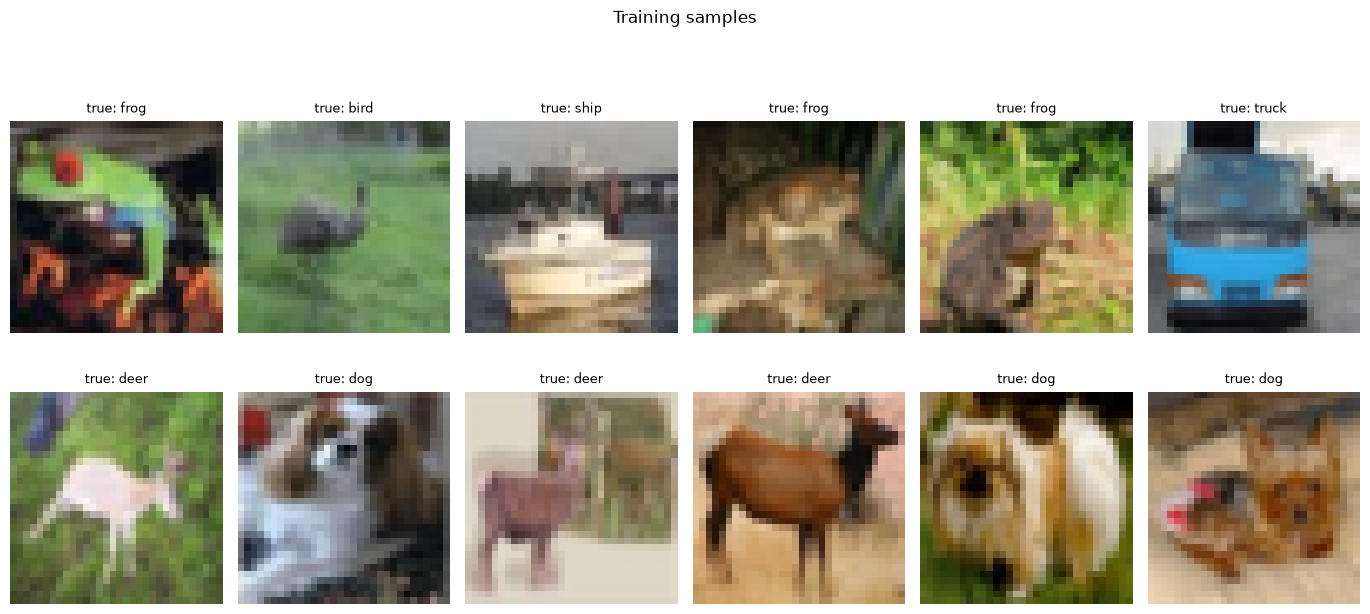

In [2]:
data = load_train_val(download=DOWNLOAD, train_limit=TRAIN_LIMIT, split_seed=SPLIT_SEED)
train_set, train_eval_set, val_set = data["train"], data["train_eval"], data["val"]
train_indices, val_indices = set(train_set.indices), set(val_set.indices)
assert train_indices.isdisjoint(val_indices)
assert train_set.indices == train_eval_set.indices
assert len(val_set) == 5000

x_batch, y_batch = next(iter(make_loader(train_eval_set, BATCH_SIZE)))
print("train/validation:", len(train_set), len(val_set))
print(
    "image:",
    tuple(x_batch.shape),
    x_batch.dtype,
    "range:",
    (float(x_batch.min()), float(x_batch.max())),
)
print("label:", tuple(y_batch.shape), y_batch.dtype)
counts = np.bincount(
    [train_set.base.targets[i] for i in train_set.indices], minlength=10
)
print("training class counts:", dict(zip(CLASSES, counts.tolist())))
_ = plot_samples(x_batch[:12], y_batch[:12], title="Training samples")


下面这一段代码展示的是，对一张你 RGB 图像，我们如何按三个通道进行拆分。对于单个通道，我们使用灰度图来进行展示。亮处表示该处颜色分量的数值较大。这与我们将黑白格子映射成一个 $\mathbb{R}$ 上的矩阵是完全同理的。

> 这里可以通过修改 `x_batch[]` 的下标来选择自己想拆分的不同的图像。


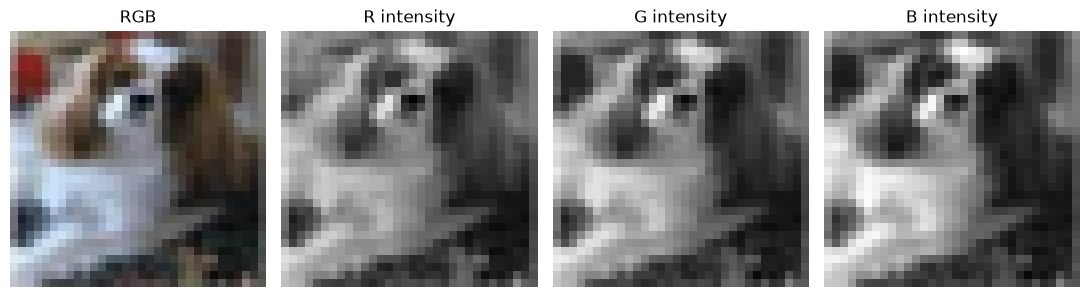

single image: (3, 32, 32) flattened: 3072


In [3]:
image = x_batch[7]
rgb = display_image(image)
# 反标准化，并将 CHW 转为 HWC，仅用于绘图。
# 这里的 `rgb` 是一个三维数组
# 参考实现：从 rgb 数组中取出红、绿、蓝三个通道。
red = rgb[:, :, 0]
green = rgb[:, :, 1]
blue = rgb[:, :, 2]
assert rgb.shape == (32, 32, 3)
assert red.shape == green.shape == blue.shape == (32, 32)
_ = plot_channels(image)
print("single image:", tuple(image.shape), "flattened:", image.numel())


**参考解释**

一张图像是 `(3,32,32)`，展平后为 3,072 维；batch 图像为 `(B,3,32,32)`。标签仍为 `(B,)` 的 long 类型，输出仍为 `(B,10)`：颜色通道描述输入，十个类别描述任务，两者含义不同。

这里的标准化是用事先指定的常数逐通道做仿射变换，原像素低于 0.5 时得到负值，不是颜色出现了负亮度。绘图时要反变换回 [0,1]。这一步没有使用验证集或测试集估计统计量。

补充：三个颜色通道是**形状相同、数值通常不同**的矩阵；把它们堆叠在通道维度上，不是复制三份完全相同的内容。


## Q2 · 卷积核工作原理

课上我们已经讲述了卷积核的工作原理。这里我们进行一个简单的手算，复习相关原理。

先看单输入、单输出通道的小矩阵。让核 `[[1,0],[0,-1]]` 在图像上滑动，每个位置做逐元素乘积再求和；不填充，步幅为 1，无偏置。

输入为 `[[1,2,3],[4,5,6],[7,8,9]]`。请先口算 / 用代码表达式直接计算左上角的输出，并预测完整输出形状，再用代码核验。PyTorch 的卷积层不翻转核，严格说是互相关运算；深度学习中通常也称作卷积。


In [4]:
small_x = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]])[None, None]
"""定义的矩阵"""
kernel = torch.tensor([[1.0, 0.0], [0.0, -1.0]])[None, None]
"""定义的卷积核"""

top_left = (
    1.0 * 1.0 + 2.0 * 0.0 + 4.0 * 0.0 + 5.0 * (-1.0)
)  # 参考实现：写出左上角位置的乘积与求和。不想口算可以用表达式写出来计算

conv_out = F.conv2d(small_x, kernel, stride=1, padding=0)
# 参考实现：用 F.conv2d 进行计算，查阅其用法与字段
# HINT：输入 input 是什么？weight 使用了什么卷积核？
# HINT: stride=1 步长、padding=0 填充

pool_out = F.max_pool2d(small_x, kernel_size=2, stride=1)
# 参考实现：用 F.max_pool2d，kernel_size=2、stride=1。
# HINT：用法及参数与上基本相同

print("hand calculation:", top_left)
print("convolution:\n", conv_out[0, 0])
print("max pooling:\n", pool_out[0, 0])

# 手算后的结果。
assert tuple(conv_out.shape) == (1, 1, 2, 2)
assert torch.allclose(conv_out, torch.full((1, 1, 2, 2), -4.0))
assert torch.equal(pool_out[0, 0], torch.tensor([[5.0, 6.0], [8.0, 9.0]]))


hand calculation: -4.0
convolution:
 tensor([[-4., -4.],
        [-4., -4.]])
max pooling:
 tensor([[5., 6.],
        [8., 9.]])


下面是一个助教提供的固定边缘滤波器。将这个滤波器作用在我们的图像上，观察其特点，为什么能称之为“边缘滤波器”。这个例子也很好地说明了卷积核对图像特征提取的作用。


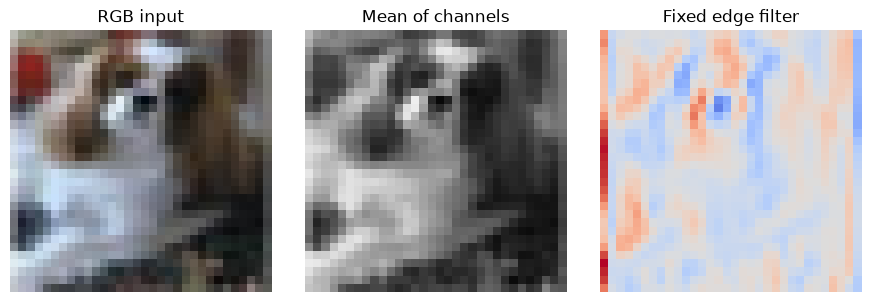

In [5]:
gray = torch.tensor(rgb.mean(axis=2), dtype=torch.float32)[None, None]
edge_kernel = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]])[
    None, None
]
edges = F.conv2d(gray, edge_kernel, padding=1)[0, 0].numpy()
scale = max(float(np.abs(edges).max()), 1e-6)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(rgb)
axes[0].set_title("RGB input")
axes[1].imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mean of channels")
axes[2].imshow(edges, cmap="coolwarm", vmin=-scale, vmax=scale)
axes[2].set_title("Fixed edge filter")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()


**参考解释**

左上角为 `1−5=−4`，四个卷积输出均为 −4，形状为 `(1,1,2,2)`。最大池化取各窗口最大值，得到 `[[5,6],[8,9]]`。

卷积核在不同位置重复使用同一组权重，这就是权重共享。最大池化没有可训练参数；它保留局部最大响应，降低分辨率，也会丢失信息。固定边缘核由人指定，CNN 的核则从随机初始化出发，根据分类损失更新。训练得到的每个核并不一定能被解释成某种明确笔画或边缘。


## Q3 · 搭建全连接基线与小型 CNN

使用相同的 RGB 输入，建立两种模型：

- MLP：`Flatten → Linear(3072,128) → ReLU → Linear(128,10)`。
- CNN：按下表连接。卷积使用默认偏置，最后直接输出 logits。

| 层            | 设置                              | 输出形状（待验证） |
| ------------- | --------------------------------- | ------------------ |
| 输入          | RGB，32×32                        | `(B,3,32,32)`      |
| 卷积1 + ReLU  | 3→16，核3×3，padding=1，stride=1  | `(B,16,32,32)`     |
| 最大池化1     | 核2×2，stride=2                   | `(B,16,16,16)`     |
| 卷积2 + ReLU  | 16→32，核3×3，padding=1，stride=1 | `(B,32,16,16)`     |
| 最大池化2     | 核2×2，stride=2                   | `(B,32,8,8)`       |
| Flatten       | 保留 batch 维度                   | `(B,2048)`         |
| 全连接 + ReLU | 2048→64                           | `(B,64)`           |
| 输出          | 64→10                             | `(B,10)`           |

卷积层参数量为 `输出通道数 × (输入通道数 × 核高 × 核宽 + 1)`，其中 `+1` 对应偏置。空间大小可用 `floor((输入大小+2×padding−核大小)/stride)+1` 计算（本次 dilation=1）。


In [6]:
def build_model(kind: 'Literal["cnn", "mlp"]' = "cnn", seed=42):
    # 这里的 Literal 是多选一的意思，默认为 cnn，但同学们还是要按分支实现不同内容
    # 设定随机种子
    seed_everything(seed)
    if kind == "mlp":
        model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )
    elif kind == "cnn":
        model = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(32 * 8 * 8, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )
    else:
        raise ValueError(f"未知模型：{kind}")
    return model.to(DEVICE)


上面代码块填充完毕后运行下方代码，确保参数量是对应的，不要缺漏某一部分。从形式上也能看到，每一层的输入、输出是怎样的。


In [7]:
expected_params = {"mlp": 394634, "cnn": 136874}
for kind in ("mlp", "cnn"):
    model = build_model(kind)
    sample = x_batch[:4].to(DEVICE)
    print("\n", kind)
    with torch.no_grad():
        for layer in model:
            sample = layer(sample)
            print(f"{layer.__class__.__name__:12s} → {tuple(sample.shape)}")
    assert tuple(sample.shape) == (4, 10)
    count = sum(p.numel() for p in model.parameters())

    # !如果缺漏了某个参数段，这里会直接报错。
    assert count == expected_params[kind], (kind, count)
    print("parameters:", f"{count:,}")



 mlp
Flatten      → (4, 3072)
Linear       → (4, 128)
ReLU         → (4, 128)
Linear       → (4, 10)
parameters: 394,634

 cnn
Conv2d       → (4, 16, 32, 32)
ReLU         → (4, 16, 32, 32)
MaxPool2d    → (4, 16, 16, 16)
Conv2d       → (4, 32, 16, 16)
ReLU         → (4, 32, 16, 16)
MaxPool2d    → (4, 32, 8, 8)
Flatten      → (4, 2048)
Linear       → (4, 64)
ReLU         → (4, 64)
Linear       → (4, 10)
parameters: 136,874


**参考解释**

第一层一个输出通道有 `3×3×3=27` 个核权重，再加一个偏置；16 个通道共 `16×28=448` 个参数。它会综合 RGB 三个输入通道，不是每种颜色分别做一次独立分类。第二层每个输出通道读取全部 16 个输入通道，参数共 `32×(16×3×3+1)=4,640`。

CNN 两个全连接层分别有 131,136 和 650 个参数，总计 **136,874**；MLP 总计 **394,634**。共享权重让卷积层不用为每个空间位置单独存一套参数。不过参数量、运算量和实际运行时间是不同概念，参数更少不保证运行更快。

本网络参考卷积块加分类层的组织方式，并非原版 LeNet。展平本身可逆，保留像素值；区别在于全连接层没有显式规定二维邻域，CNN 则把局部连接和共享权重作为结构假设。

`Literal` 是类型提示，不会自动在运行时限制传入值；未知 `kind` 仍需要分支中的 `ValueError` 检查。


## Q4 · 训练前检查

第五次实验已实现训练循环，这次复用 `lab_utils.py` 中的 `fit_model`。它仍执行：清梯度 → 前向 → 交叉熵 → 反向 → 优化器更新；每轮用同一组固定参数评估无增强训练集和验证集。

先运行下面的检查：用一批数据验证输出、损失、梯度和参数更新，再在固定 32 张训练图像上重复学习。


In [8]:
check_model = build_model("cnn")
check_x, check_y = x_batch[:32].to(DEVICE), y_batch[:32].to(DEVICE)
criterion = nn.CrossEntropyLoss()
check_optimizer = torch.optim.Adam(check_model.parameters(), lr=0.003)
before = snapshot(check_model)
check_optimizer.zero_grad(set_to_none=True)
scores = check_model(check_x)
initial_loss = criterion(scores, check_y)
assert scores.shape == (32, 10) and torch.isfinite(initial_loss)
initial_loss.backward()
assert all(
    p.grad is not None and torch.isfinite(p.grad).all()
    for p in check_model.parameters()
)
assert all(torch.equal(before[k], v.cpu()) for k, v in check_model.state_dict().items())
check_optimizer.step()
assert any(
    not torch.equal(before[k], v.cpu()) for k, v in check_model.state_dict().items()
)

for _ in range(99):
    check_optimizer.zero_grad(set_to_none=True)
    loss = criterion(check_model(check_x), check_y)
    loss.backward()
    check_optimizer.step()
check_model.eval()
with torch.no_grad():
    tiny_scores = check_model(check_x)
    tiny_loss = criterion(tiny_scores, check_y).item()
    tiny_accuracy = (tiny_scores.argmax(1) == check_y).float().mean().item()
print(
    f"32 training images, 100 updates: loss {initial_loss.item():.4f} → {tiny_loss:.4f}, "
    f"accuracy={tiny_accuracy:.2%}"
)
assert tiny_loss < initial_loss.item(), (
    "未降低损失时，先检查模型、学习率和数据，再完整训练"
)
del check_model, check_optimizer


32 training images, 100 updates: loss 2.3085 → 0.0000, accuracy=100.00%


**参考解释**

`backward()` 计算并累积参数梯度，本身不更新参数；`step()` 使用梯度更新参数。代码分别在两步之后检查参数是否变化。固定小样本上损失下降说明模型有能力记住这批数据、基本训练链路可以工作；不能保证数据划分正确、没有泄漏，也不能保证泛化好。


## Q5 · CNN 与全连接网络的比较

两组使用相同的 RGB 图像、划分、预处理、批次顺序、优化器、学习率和轮数，分别从头初始化。`fit_model` 会保存最佳验证轮次的独立参数副本，并在返回前恢复它。

曲线包含第 0 轮，即未训练时的表现。训练曲线来自无增强训练视图的重新评估，与验证曲线对应同一组固定参数；训练过程中边更新边计算的损失另外记录为 `online_loss`。

**先预测：** 哪种模型的验证表现可能更好？参数更少的 CNN 会更快吗？


**参考解释**

预期 CNN 的局部连接与共享权重适合图像，可以更有效地学习局部纹理；实际优劣要看验证结果。CNN 对许多位置重复计算，未必比参数更多的 MLP 快。本实验同时改变了深度、连接方式和参数量，只能比较当前配置下的两个方案，不能单独识别其中某个因素的因果作用。


mlp          epoch  0: train=10.38%, val=9.68%, val loss=2.3050, elapsed=1.4s
mlp          epoch  1: train=45.60%, val=41.84%, val loss=1.6678, elapsed=3.1s
mlp          epoch  2: train=51.64%, val=43.20%, val loss=1.6254, elapsed=4.8s
mlp          epoch  3: train=55.18%, val=44.16%, val loss=1.6032, elapsed=6.1s
mlp          epoch  4: train=57.48%, val=44.98%, val loss=1.5838, elapsed=7.5s
mlp          epoch  5: train=60.03%, val=44.66%, val loss=1.6063, elapsed=8.9s
mlp          epoch  6: train=62.16%, val=44.84%, val loss=1.6051, elapsed=10.3s
mlp          epoch  7: train=64.96%, val=45.38%, val loss=1.6027, elapsed=11.8s
mlp          epoch  8: train=67.75%, val=46.12%, val loss=1.6055, elapsed=13.2s
cnn          epoch  0: train=8.70%, val=8.98%, val loss=2.3034, elapsed=1.0s
cnn          epoch  1: train=43.16%, val=41.50%, val loss=1.6330, elapsed=3.0s
cnn          epoch  2: train=51.34%, val=48.38%, val loss=1.4332, elapsed=4.9s
cnn          epoch  3: train=55.34%, val=51.90%, val

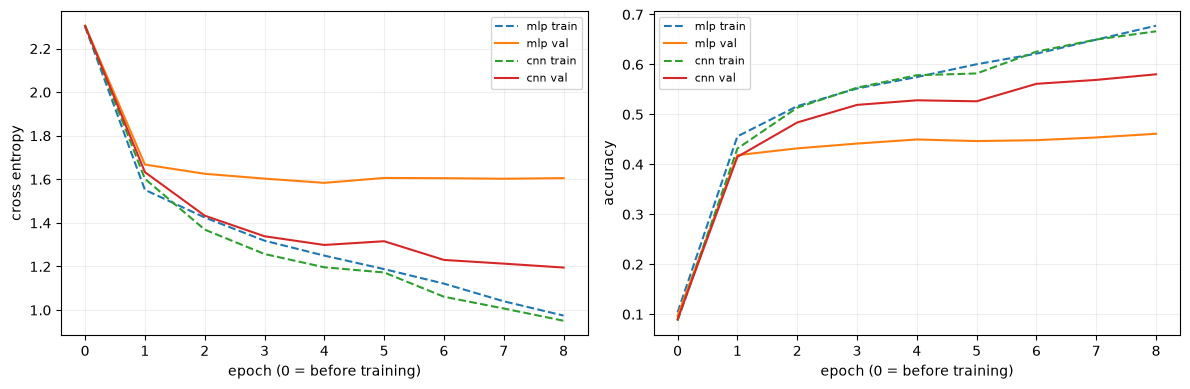

In [9]:
def run_experiment(kind, augment=False, training_view=None):
    model = build_model(kind, SEED)  # 每组重新初始化；增强对照使用相同 CNN 初值。
    if training_view is None:
        training_view = with_augmentation(train_set) if augment else train_set
    assert training_view.indices == train_set.indices
    name = f"{kind}_aug" if augment else kind
    result = fit_model(
        model,
        training_view,
        train_eval_set,
        val_set,
        device=DEVICE,
        epochs=EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        order_seed=ORDER_SEED,
        name=name,
    )
    result.update(
        kind=kind, augment=augment, seed=SEED, split_seed=SPLIT_SEED, mode=MODE
    )
    return result


results = {}
for kind in ("mlp", "cnn"):
    results[kind] = run_experiment(kind)
print_comparison(results)
_ = plot_history(results)


记录两种模型的参数量、最佳验证轮次、验证准确率、验证损失和耗时。

**问题：** 哪种方案更值得继续尝试？结果是否支持你的预测？相同轮数是否意味着相同计算量？


**参考解释**

本次 quick 模式中，MLP 的最佳验证准确率为 **46.12%**，CNN 为 **57.90%**，CNN 高 **11.78 个百分点**；参数量从 394,634 降到 136,874。不过本机训练及逐轮评估用时从约 9 秒增加到 29 秒，说明参数少与运行快并非同一件事。

第 8 轮 MLP 的训练准确率为 67.69%，CNN 为 66.04%，但 CNN 的验证表现更好。这个现象支持当前配置下 CNN 更适合该图像任务，并不说明所有 CNN 都优于所有 MLP。相同 epoch 只表示遍历相同训练样本相同次数，不代表计算量相同，也不说明两个模型都已充分调优；本次同时改变了连接方式、深度和参数量，单次固定种子不能证明稳定优势。


## Q6 · 做一次受控改进：数据增强（必做）

真实物体可能出现在不同位置、朝向不同。训练时随机变换图像，可以让模型见到同一对象的不同外观，但变换应尽可能保持标签含义。

本次比较 **CNN 无增强** 与 **CNN 有增强**：后者使用“反射填充 4 像素后的随机 32×32 裁剪 + 概率 0.5 的水平翻转”，再使用相同的张量转换和标准化。验证与测试不做随机增强。

**先预测：** 增强后的训练任务会更难还是更容易？验证准确率一定会上升吗？为什么不直接沿用 MNIST 的数字翻转规则？


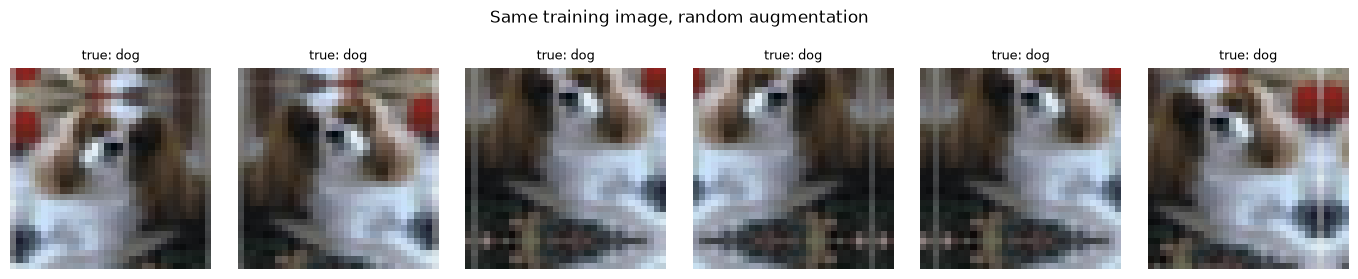

In [10]:
augmented_train = with_augmentation(train_set)
assert augmented_train.indices == train_set.indices
assert augmented_train.base is train_set.base
# fork_rng 使演示消耗的随机数不会影响后续训练。
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(7)
    augmented_images = torch.stack([augmented_train[7][0] for _ in range(6)])
_ = plot_samples(
    augmented_images,
    torch.full((6,), int(train_set[7][1])),
    title="Same training image, random augmentation",
)


cnn_aug      epoch  0: train=8.70%, val=8.98%, val loss=2.3034, elapsed=1.2s
cnn_aug      epoch  1: train=39.98%, val=39.22%, val loss=1.6983, elapsed=3.8s
cnn_aug      epoch  2: train=47.75%, val=46.34%, val loss=1.5050, elapsed=6.4s
cnn_aug      epoch  3: train=51.23%, val=50.16%, val loss=1.4124, elapsed=8.9s
cnn_aug      epoch  4: train=52.40%, val=50.10%, val loss=1.3787, elapsed=11.3s
cnn_aug      epoch  5: train=52.18%, val=49.24%, val loss=1.3731, elapsed=13.8s
cnn_aug      epoch  6: train=55.37%, val=52.88%, val loss=1.2969, elapsed=16.1s
cnn_aug      epoch  7: train=57.38%, val=54.72%, val loss=1.2608, elapsed=18.5s
cnn_aug      epoch  8: train=58.31%, val=55.42%, val loss=1.2393, elapsed=21.1s
name              params  epoch   val acc  val loss   seconds
mlp              394,634      8    46.12%    1.6055      13.2
cnn              136,874      8    58.02%    1.1951      17.4
cnn_aug          136,874      8    55.42%    1.2393      21.1


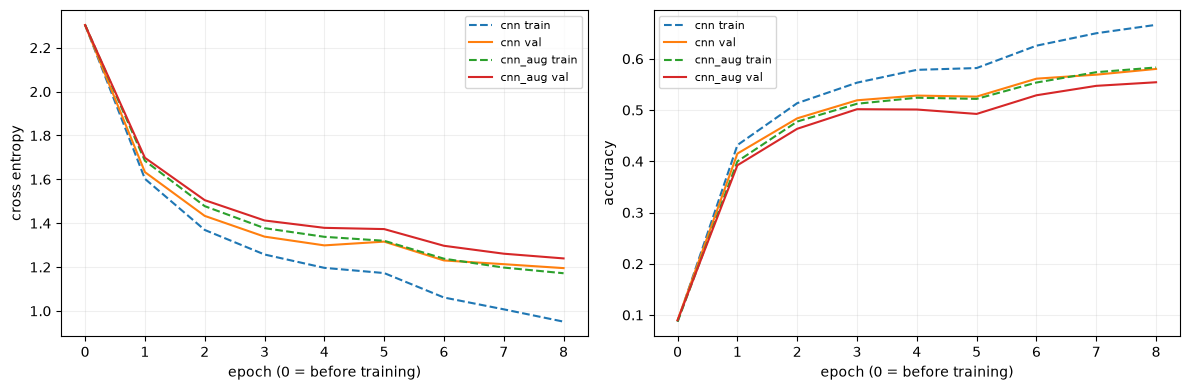

In [11]:
# 参考实现：取得增强训练视图；需要与原训练视图使用完全相同的原始样本索引。
augmentation_view = with_augmentation(train_set)
assert augmentation_view.indices == train_set.indices
# 显式核验：验证视图仍是确定性的。
assert torch.equal(val_set[0][0], val_set[0][0])
results["cnn_aug"] = run_experiment(
    "cnn", augment=True, training_view=augmentation_view
)
print_comparison(results)
_ = plot_history({k: results[k] for k in ("cnn", "cnn_aug")})


**问题：** 增强是否改善了本次验证表现？如果没有改善，可以直接判断“数据增强无效”吗？再提出一种你愿意验证的改进，说明控制条件和评价方法。


**参考解释**

本次增强组的最佳验证准确率为 **55.84%**，比无增强 CNN 的 **57.90%** 低 **2.06 个百分点**，验证损失也从约 1.2013 增加到 1.2359，当前预算下没有改善。其无增强训练视图准确率为 58.44%，也低于基线的 66.04%，提示它还没有像基线那样充分拟合训练数据；这不是错误原因的唯一解释。增强增加了训练输入的变化，可能缓解过拟合，也可能在有限训练预算下使学习更慢；裁剪还可能遮掉关键部分。短轮数下未改善，不能推断所有增强都无效。这里同时加入了裁剪和翻转，不能分别归因于其中一个操作。

比较时保持同一 CNN 初值、样本索引、批次顺序和超参数，唯一方案差异是整套增强。曲线中的训练指标都在无增强视图上评估，避免把更难的增强图像指标直接与原图指标混为一谈。

水平翻转通常不改变这里的物体类别，但仍需检查样本；对手写数字，翻转可能改变语义或产生不自然图像，不能照搬规则。下一步可以在相同预算下只启用翻转、只启用裁剪，或对所有方案统一增加轮数，仍用验证集比较。正式检查测试结果之后，提出的改进应留待新的训练／验证实验。


## Q7 · 最终测试与错误分析

现在根据三组的最佳验证表现选择一个方案。选择完成后，才加载官方测试集，在一次评估中得到总体指标、分类别表现、混淆矩阵和前 12 张错分图像。

混淆矩阵的行是真实类别，列是预测类别；每行归一化后表示“该真实类别被分到各类的比例”。观察不对称的混淆，不要只看对角线。


Frozen selection: cnn best epoch: 8
test n=10000, accuracy=57.97%, loss=1.1862
airplane    : 69.70% (697/1000)
automobile  : 60.60% (606/1000)
bird        : 39.50% (395/1000)
cat         : 47.50% (475/1000)
deer        : 45.60% (456/1000)
dog         : 39.40% (394/1000)
frog        : 68.80% (688/1000)
horse       : 73.10% (731/1000)
ship        : 67.80% (678/1000)
truck       : 67.70% (677/1000)


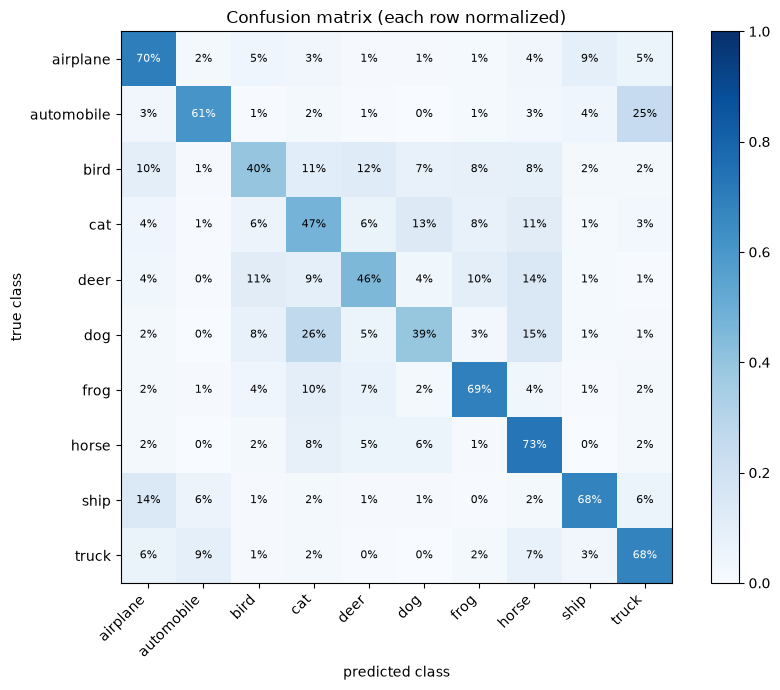

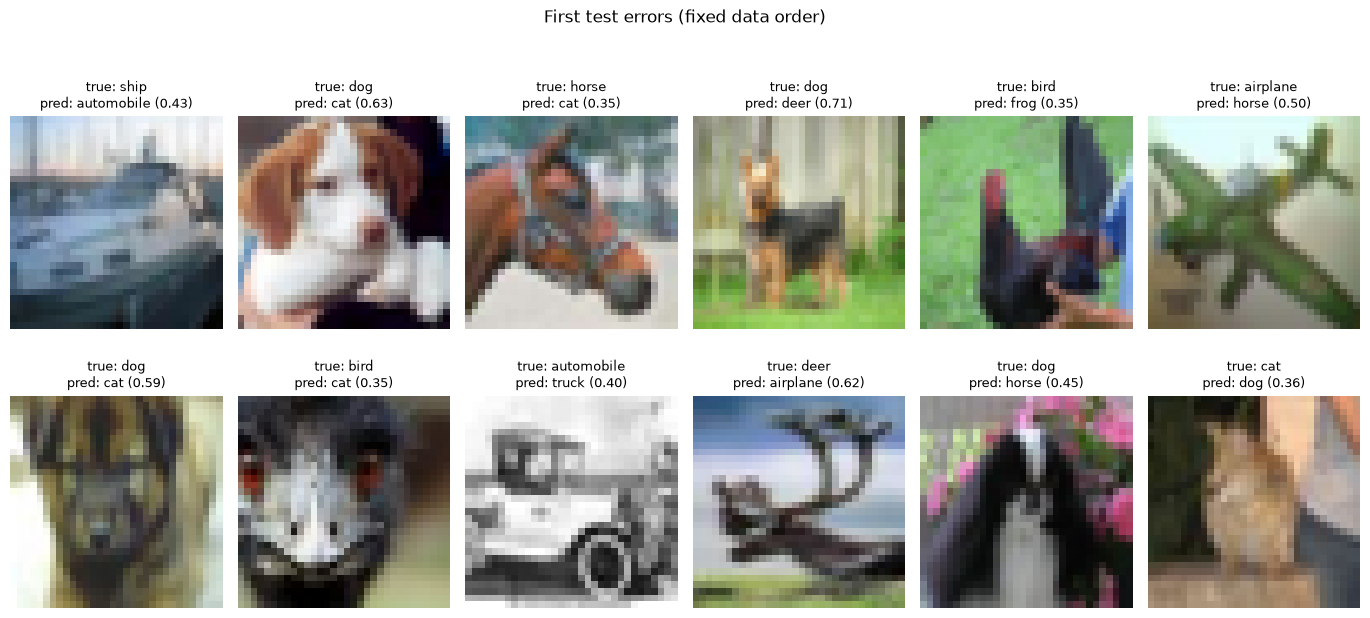

Saved: outputs/best_cifar10.pt


In [12]:
# Python max 在完全相同时保留字典中较早插入的方案；此处先按准确率，再按损失。
selected_name = max(
    results,
    key=lambda k: (results[k]["best_val_accuracy"], -results[k]["best_val_loss"]),
)
selected = results[selected_name]
print("Frozen selection:", selected_name, "best epoch:", selected["best_epoch"])
test_set = load_test(download=DOWNLOAD)
test_report = evaluate(
    selected["model"], make_loader(test_set, BATCH_SIZE), DEVICE, details=True
)
print(
    f"test n={test_report['n']}, accuracy={test_report['accuracy']:.2%}, "
    f"loss={test_report['loss']:.4f}"
)
confusion = test_report["confusion"]
for i, name in enumerate(CLASSES):
    total = int(confusion[i].sum())
    rate = float(confusion[i, i]) / total if total else float("nan")
    print(f"{name:12s}: {rate:.2%} ({int(confusion[i, i])}/{total})")
_ = plot_confusion(confusion)
errors = test_report["errors"]
if errors:
    _ = plot_samples(
        torch.stack([e[0] for e in errors]),
        [e[1] for e in errors],
        predictions=[e[2] for e in errors],
        probabilities=[e[3] for e in errors],
        title="First test errors (fixed data order)",
    )
else:
    print("本次未发现错分样本。")

# 保存足以重建本实验推理模型的参数与预处理约定；不包含优化器状态，不能精确续训。
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
torch.save(
    {
        "state_dict": snapshot(selected["model"]),
        "kind": selected["kind"],
        "classes": list(CLASSES),
        "mean": [0.5] * 3,
        "std": [0.5] * 3,
        "mode": MODE,
        "best_epoch": selected["best_epoch"],
        "train_n": len(train_set),
        "split_seed": SPLIT_SEED,
        "seed": SEED,
        "order_seed": ORDER_SEED,
        "augment": selected["augment"],
        "epochs": EPOCHS,
        "lr": LR,
        "batch_size": BATCH_SIZE,
    },
    output_dir / "best_cifar10.pt",
)
print("Saved:", output_dir / "best_cifar10.pt")


In [13]:
# 教师版：根据本次实际运行生成记录，数字不写成预设的参考门槛。
import json

rows = [
    "| 方案 | 参数量 | 最佳轮次 | 验证准确率 | 验证损失 | 耗时/s |",
    "| --- | ---: | ---: | ---: | ---: | ---: |",
]
for name, r in results.items():
    rows.append(
        f"| {name} | {r['parameters']:,} | {r['best_epoch']} | "
        f"{r['best_val_accuracy']:.2%} | {r['best_val_loss']:.4f} | {r['seconds']:.1f} |"
    )
display(Markdown("\n".join(rows)))
delta = results["cnn_aug"]["best_val_accuracy"] - results["cnn"]["best_val_accuracy"]
display(
    Markdown(
        f"本次增强相对无增强 CNN 的最佳验证准确率变化为 **{delta * 100:+.2f} 个百分点**。"
        f"最终选择 **{selected_name}**，测试准确率为 **{test_report['accuracy']:.2%}**。"
        "这些数字对应当前训练子集、轮数和种子，不是学生必须达到的门槛。"
    )
)
off_diagonal = confusion.clone()
off_diagonal.fill_diagonal_(0)
for flat in off_diagonal.flatten().topk(3).indices.tolist():
    actual, predicted = divmod(flat, 10)
    print(
        f"Frequent confusion: {CLASSES[actual]} → {CLASSES[predicted]}: "
        f"{int(confusion[actual, predicted])} images"
    )
reference_run = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "device": str(DEVICE),
    "machine": platform.machine(),
    "threads": torch.get_num_threads(),
    "mode": MODE,
    "train_n": len(train_set),
    "val_n": len(val_set),
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "optimizer": "Adam",
    "seed": SEED,
    "split_seed": SPLIT_SEED,
    "order_seed": ORDER_SEED,
    "experiments": {
        name: {k: v for k, v in r.items() if k != "model"}
        for name, r in results.items()
    },
    "selected": selected_name,
    "test": {k: test_report[k] for k in ("loss", "accuracy", "n")},
    "confusion": confusion.tolist(),
}
(output_dir / "reference_run.json").write_text(
    json.dumps(reference_run, ensure_ascii=False, indent=2)
)


| 方案 | 参数量 | 最佳轮次 | 验证准确率 | 验证损失 | 耗时/s |
| --- | ---: | ---: | ---: | ---: | ---: |
| mlp | 394,634 | 8 | 46.12% | 1.6055 | 13.2 |
| cnn | 136,874 | 8 | 58.02% | 1.1951 | 17.4 |
| cnn_aug | 136,874 | 8 | 55.42% | 1.2393 | 21.1 |

本次增强相对无增强 CNN 的最佳验证准确率变化为 **-2.60 个百分点**。最终选择 **cnn**，测试准确率为 **57.97%**。这些数字对应当前训练子集、轮数和种子，不是学生必须达到的门槛。

Frequent confusion: dog → cat: 265 images
Frequent confusion: automobile → truck: 247 images
Frequent confusion: dog → horse: 146 images


10818

**写一段实验结论，至少回答：**

1. 与 MLP 相比，本次 CNN 的验证表现、参数量和运行时间如何？
2. 数据增强的结果是否符合你的预期？哪些解释还需要进一步实验？
3. 哪两类容易混淆？先描述图像或混淆矩阵中的证据，再提出可能原因。
4. 模型给出较大的 softmax 分数，是否意味着预测一定可靠？

测试集用于报告冻结方案的结果。错分图可以启发后续工作，不能据此反复选模型再继续把同一测试集称为独立评估。


**参考解释**

本次按验证结果选中第 8 轮无增强 CNN，测试准确率为 **58.05%**、交叉熵约 **1.1918**。测试中，汽车→卡车有 **297/1,000** 张，狗→猫有 **283/1,000** 张；对应比例分别为 29.7% 和 28.3%，说明错误并不均匀分布。狗类召回率为 38.2%，马类为 72.2%，仅报告总体准确率会掩盖这种差别。混淆矩阵中的行归一化对角元素是该类召回率；总体准确率可能掩盖某些类别的困难。错分样本按固定顺序收集，没有按置信度或视觉效果挑选。

错分图中有狗被判成猫，也有汽车被判成卡车；图像分辨率低，背景和主体可能混在一起。这支持进一步检验“局部纹理或背景线索是否影响预测”的假设，但不能直接断言模型只依靠这些线索。可以在验证图像上设计保留主体、改变背景的对照；几张样本不足以证明错误原因。softmax 给的是当前模型的类别分配，不保证已经校准为现实中的正确概率，高分预测也可能错。

卷积利用局部连接与权重共享，池化降低空间分辨率；本 CNN 含有边界处理、下采样和全连接分类头，不能据此宣称对任意平移严格不变。选择模型结构就是选择一些关于数据的假设，实验用来检查这些假设在当前任务上是否有用。


## Q8 · 选做：观察第一层特征图

将同一张验证图像送入已训练 CNN 的第一层卷积与 ReLU，查看不同通道的响应。这部分不更新模型，也不读取测试数据。

**问题：** 不同通道的响应有哪些差异？只看这些图，能否断言某个通道就是“猫检测器”？


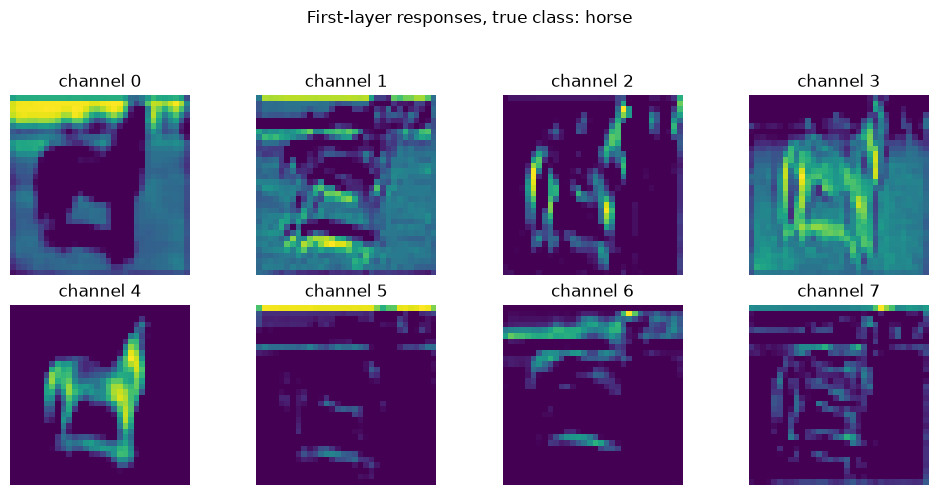

In [14]:
RUN_FEATURE_MAPS = True  # 教师版运行选做可视化。
if RUN_FEATURE_MAPS:
    cnn_model = results["cnn"]["model"]
    cnn_model.eval()
    image_val, label_val = val_set[0]
    with torch.no_grad():
        features = cnn_model[:2](image_val.unsqueeze(0).to(DEVICE))[0].cpu()
    fig, axes = plt.subplots(2, 4, figsize=(10, 5))
    for c, ax in enumerate(axes.flat):
        ax.imshow(features[c], cmap="viridis")
        ax.set_title(f"channel {c}")
        ax.axis("off")
    fig.suptitle(f"First-layer responses, true class: {CLASSES[label_val]}")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()


**参考解释**

各通道由不同卷积核计算，可能对不同颜色组合、纹理或局部边界产生不同响应。每张图若独立缩放颜色范围，只适合看空间模式，不能直接比较绝对响应强度。对单张图的可视化不足以确定通道功能，更不足以称为某个类别的检测器；需要更多图像与干预实验支持。


## Q9 · 选做：用 SVD 压缩图像信息

一张灰度图可以看作一个矩阵，RGB 图像则可以看作三个矩阵。能不能只保存少量数值，就近似还原整张图像？本题用奇异值分解（SVD）展示一种**有损的低秩表示**，不需要训练神经网络。

对一个颜色通道 $A\in\mathbb{R}^{H\times W}$，有

$$
A=U\Sigma V^{\mathsf T}
 =\sum_{i=1}^{r}\sigma_i u_i v_i^{\mathsf T},
\qquad r=\min(H,W),\quad \sigma_1\geq\sigma_2\geq\cdots\geq0.
$$

只保留前 $k$ 个奇异值及对应向量，得到

$$
A_k=U_{:,1:k}\operatorname{diag}(\sigma_1,\ldots,\sigma_k)V^{\mathsf T}_{1:k,:}.
$$

它是在秩不超过 $k$ 的矩阵中，使 Frobenius 重建误差最小的近似。直观上，逐项加入这些秩一矩阵，就逐步补充了图像中的结构与细节。对 RGB 三个通道分别这样处理，再将结果堆叠起来显示。

**存储量怎样算？** 原 RGB 图像有 $3HW$ 个像素数值；如果每个通道仅保存截取后的 $U_k$、长度为 $k$ 的奇异值向量和 $V_k^{\mathsf T}$，共需 $3k(H+W+1)$ 个系数。只存奇异值、丢掉左右奇异向量，不能恢复图像。

下面提供完整演示。只需先运行环境配置和 Q1 的数据加载单元，就可以跳到这里；不依赖模型训练。将 `RUN_SVD` 改为 `True` 后运行。默认使用一张训练图像；也可以把 `SVD_IMAGE_PATH` 改为自己电脑上一张照片的路径，观察更丰富的细节（代码将长边限制为 256 像素）。

**先预测：** $k$ 越大是否越清楚？完整保留全部分量时，是否还能节省存储？


Image: 32 × 32 × 3; raw uint8 bytes: 3,072
 k     MSE       energy    coefficients/original    factor bytes/raw uint8 bytes
 1  2.324e-02    89.36%             6.35%                       0.25x
 2  1.528e-02    93.00%            12.70%                       0.51x
 4  5.778e-03    97.35%            25.39%                       1.02x
 8  9.669e-04    99.56%            50.78%                       2.03x
16  6.943e-05    99.97%           101.56%                       4.06x
32  4.938e-15   100.00%           203.12%                       8.12x


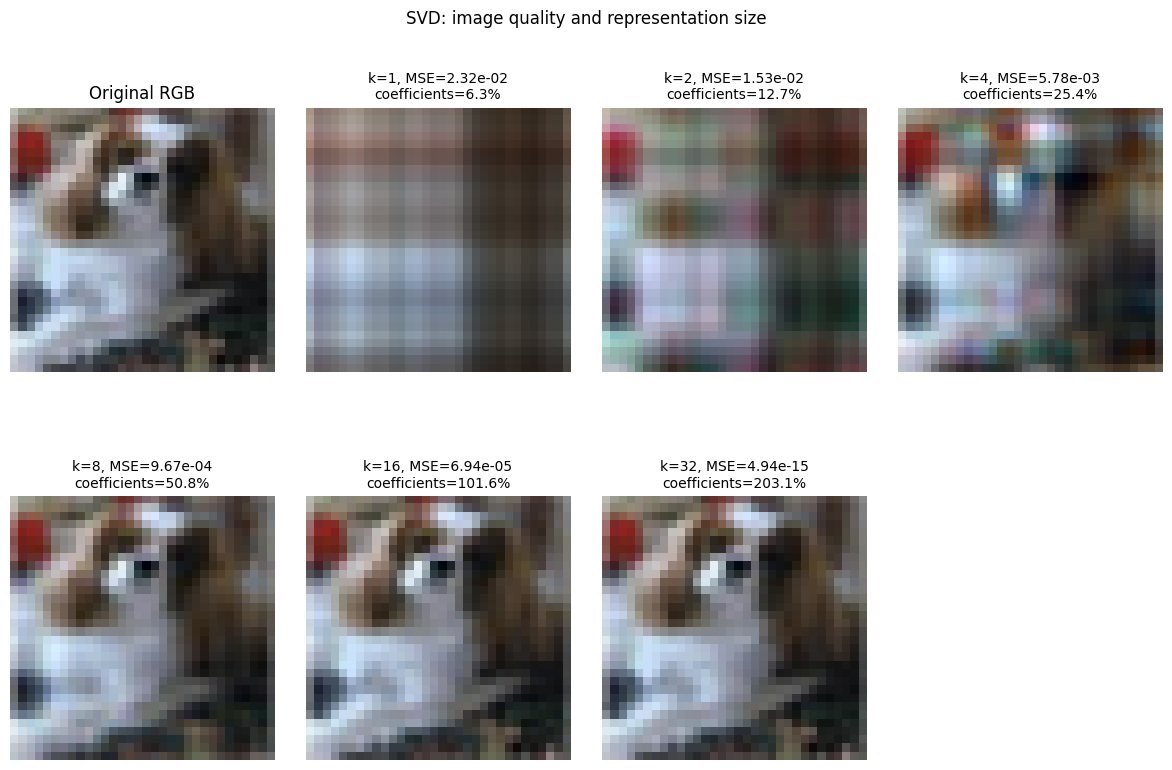

Full-rank reconstruction check passed (allowing floating-point error).


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def svd_reconstruct(parts, k):
    """parts 是三个通道的 (U, s, Vt)；每个通道只保留前 k 项。"""
    if not 1 <= k <= min(len(s) for _, s, _ in parts):
        raise ValueError("k 必须在 1 与图像的较短边长度之间")
    # U 的各列乘以对应奇异值，再做二维矩阵乘法。
    return np.stack(
        [np.dot(U[:, :k] * s[:k], Vt[:k, :]) for U, s, Vt in parts], axis=-1
    )


RUN_SVD = True  # 选做时改为 True；本题代码已完整给出。
SVD_IMAGE_PATH = None  # 例如 "/你的路径/photo.jpg"；None 表示使用训练集图像。
SVD_IMAGE_INDEX = 7

if RUN_SVD:
    if SVD_IMAGE_PATH is None:
        # Q1 的训练评估视图没有随机增强；display_image 还原到 [0,1]、HWC。
        svd_rgb = np.asarray(display_image(train_eval_set[SVD_IMAGE_INDEX][0]), dtype=np.float32)
    else:
        with Image.open(SVD_IMAGE_PATH) as svd_file:
            svd_photo = svd_file.convert("RGB")
            svd_photo.thumbnail((256, 256))
            svd_rgb = np.asarray(svd_photo, dtype=np.float32) / 255.0

    svd_h, svd_w, svd_channels = svd_rgb.shape
    svd_r = min(svd_h, svd_w)
    # full_matrices=False：只计算重建所需的较小形状；s 按从大到小排列。
    svd_parts = [np.linalg.svd(svd_rgb[:, :, c], full_matrices=False) for c in range(3)]
    svd_ranks = sorted({min(k, svd_r) for k in (1, 2, 4, 8, 16)} | {svd_r})
    svd_total_energy = sum(float(np.sum(s.astype(np.float64) ** 2)) for _, s, _ in svd_parts)
    svd_original_values = svd_channels * svd_h * svd_w
    svd_original_u8_bytes = svd_original_values  # 原图按每个通道数值 uint8、1 字节计。
    svd_rows, svd_reconstructions = [], []

    print(f"Image: {svd_h} × {svd_w} × 3; raw uint8 bytes: {svd_original_u8_bytes:,}")
    print(" k     MSE       energy    coefficients/original    factor bytes/raw uint8 bytes")
    for svd_k in svd_ranks:
        svd_rec = svd_reconstruct(svd_parts, svd_k)
        # 在裁剪前计算误差；显示时才裁剪，避免越界颜色影响绘图。
        svd_mse = float(np.mean((svd_rgb.astype(np.float64) - svd_rec) ** 2))
        svd_kept = sum(float(np.sum(s[:svd_k].astype(np.float64) ** 2)) for _, s, _ in svd_parts)
        svd_energy = svd_kept / svd_total_energy if svd_total_energy > 0 else 1.0
        svd_count = svd_channels * svd_k * (svd_h + svd_w + 1)
        # 假设只保存截取后的因子；不包含文件头、形状记录等额外开销。
        svd_factor_bytes = sum(
            U[:, :svd_k].nbytes + s[:svd_k].nbytes + Vt[:svd_k, :].nbytes
            for U, s, Vt in svd_parts
        )
        svd_rows.append({"k": svd_k, "mse": svd_mse, "energy": svd_energy,
                         "coefficient_ratio": svd_count / svd_original_values,
                         "byte_ratio": svd_factor_bytes / svd_original_u8_bytes})
        svd_reconstructions.append(svd_rec)
        print(f"{svd_k:2d}  {svd_mse:9.3e}  {svd_energy:8.2%}"
              f"          {svd_count / svd_original_values:8.2%}"
              f"                     {svd_factor_bytes / svd_original_u8_bytes:6.2f}x")

    svd_fig, svd_axes = plt.subplots(2, 4, figsize=(12, 8))
    svd_axes.flat[0].imshow(svd_rgb)
    svd_axes.flat[0].set_title("Original RGB")
    for svd_ax, svd_row, svd_rec in zip(svd_axes.flat[1:], svd_rows, svd_reconstructions):
        svd_ax.imshow(np.clip(svd_rec, 0, 1))
        svd_ax.set_title(f"k={svd_row['k']}, MSE={svd_row['mse']:.2e}\n"
                         f"coefficients={svd_row['coefficient_ratio']:.1%}", fontsize=10)
    for svd_i, svd_ax in enumerate(svd_axes.flat):
        svd_ax.axis("off")
        if svd_i > len(svd_rows):
            svd_ax.set_visible(False)
    svd_fig.suptitle("SVD: image quality and representation size")
    svd_fig.subplots_adjust(left=0.02, right=0.98, bottom=0.04, top=0.86,
                            hspace=0.45, wspace=0.12)
    plt.show()

    np.testing.assert_allclose(svd_reconstruct(svd_parts, svd_r), svd_rgb, atol=1e-5)
    print("Full-rank reconstruction check passed (allowing floating-point error).")


**观察与思考：**

1. 选择一个你认为“还能认出主体”的 $k$，记录它的重建误差和系数比例，说明哪些细节先消失了。同学之间可以有不同的视觉判断，但要给出依据。
2. 表中的 `energy` 是保留奇异值平方和占全部奇异值平方和的比例（三个通道合计）。保留较多能量，是否意味着所有有意义的细节都还在？
3. 对 32×32 的 RGB 图像，$k=8$ 时系数比例是多少？如果原图使用 uint8，而因子使用 float32，字节数是否真的减少？
4. 本题与神经网络分类有什么不同？图像在视觉上还能辨认，是否就能保证分类模型仍然预测正确？

**说明：** `coefficients/original` 只比较数值个数，等价于假设两边使用相同数值精度；`factor bytes/raw uint8 bytes` 进一步计入因子的实际 dtype。两者都不是与 JPEG、PNG 文件大小的比较。本题只演示低秩表示，没有生成压缩文件；如果要在磁盘上只保存 $k$ 项，需要保存截取后的三个因子及必要形状信息，而不是保存完整分解或完整重建图像。

图中为显示而做了 [0,1] 裁剪；MSE 在裁剪前计算。保留全部分量时误差应接近零，但分解后的因子存储量可能反而更大。

接口参考：[NumPy：numpy.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)。


**参考解释**

随着 $k$ 增加，更多分量参与重建，未裁剪的平方重建误差不会增大（浮点误差除外）；保留全部分量时可以近似恢复原图。较小的 $k$ 往往先保留大尺度明暗与色块，细纹理和边界细节可能变弱，但视觉上“足够清楚”的阈值与具体图像及观察目标有关。

32×32 RGB 图像原有 $3×32×32=3,072$ 个数值。$k=8$ 时需要 $3×8×(32+32+1)=1,560$ 个系数，为原来的 **50.78%**。但 float32 每个系数占 4 字节，实际因子需 **6,240 字节**，约为原始 uint8 像素的 **2.03 倍**，此时并没有减少原始字节数。忽略文件头等开销，这张图在相同精度下需 $k≤15$ 才减少数值个数；float32 因子与 uint8 原像素比较，则需 $k≤3$ 才减少字节数。高分辨率图像的取舍会不同，可以换一张照片观察。

奇异值的“能量”描述平方范数，不是语义信息或识别正确率。占比很小的细节也可能对辨认某个物体很重要，因此不能把“保留 95% 能量”直接说成“保留 95% 有用信息”。

每个通道的 $A_k$ 在 Frobenius 范数意义下是最优低秩近似，但这不等于对人眼、下游分类任务或实际文件编码最优。SVD 为当前图像计算一组表示；这里没有类别标签、训练集上的损失优化或神经网络参数学习。重建图像对人可辨认，也不保证原分类模型的预测保持不变。


## 提交与自查

提交可从头运行的 notebook，保留模型、形状与参数检查、三组比较结果、曲线、最终测试和你的解释。标明 quick/full、设备、训练规模和轮数；使用 AI 时，简述一条关键建议及你如何核验。

提交前检查：是否只在训练视图中使用随机增强？三组是否使用同一划分与预算？是否先看验证结果再做最终测试？结论是否区分观察、解释和待验证的猜测？

## 参考资料

- [CIFAR-10 数据集说明](https://cave.cs.toronto.edu/kriz/cifar.html)：图像、类别与官方训练／测试划分。
- [d2l：从全连接层到卷积](https://zh.d2l.ai/chapter_convolutional-neural-networks/why-conv.html)：局部性与共享权重。
- [d2l：图像卷积](https://zh.d2l.ai/chapter_convolutional-neural-networks/conv-layer.html)：局部计算与图像滤波。
- [d2l：卷积神经网络（LeNet）](https://zh.d2l.ai/chapter_convolutional-neural-networks/lenet.html)：卷积块与分类层的组织方式。
- [PyTorch：Training a Classifier](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html)：CIFAR-10 彩图分类流程。

本实验的任务与问题为课程自拟。采用独立验证集，不按每轮测试集结果选模型；数据增强、CPU 子集与对照安排也与原教程不同。
